# Stacking

## Objectives
The objective of this notebook is to find out which combination of CatBoost, the lasso and a support vector machine (SVR) predicts best, and with which weights. CatBoost is a tree model, the lasso a linear model and the SVR a smooth nonlinear model, so their errors may differ. CatBoost is trained with the two outlier houses, as in the boosting notebook. The lasso and the SVR are trained without them, as in the regularisation notebook, and CatBoost alone predicts the houses outside their range. All the models are scored on all the train houses, outliers included, because the test houses can be unusual too. Section 1 explains how models are combined, section 2 builds the predictions of the three models on houses they did not see, section 3 asks whether their errors differ and where, section 4 learns the weights of the combinations and checks how well the data determines them, and section 5 saves the submission.

## 1. Blending and Stacking
A blend averages the predictions of models with fixed weights. A stack learns the weights from the data. In both cases the combination only helps if the models make different errors.
- The weights must be learned from out-of-fold predictions, which are predictions for each train house from a model that did not see it. With in-sample predictions the weights would favour the model that overfits.
- The combination is CatBoost plus a weight times the difference of each other model from CatBoost, so the weights sum to one. The weights are not negative, and they minimise the squared error of the combination.
- The weights are only estimates, so we also measure how well the data determines them, with a bootstrap, by learning them in each fold and on a second split of the folds.
- The weights are scored fairly by learning them on four of the five folds and testing them on the fifth.
- A linear model can be far wrong for a house larger than any it was fitted on, so for those houses the combination uses CatBoost alone. This is the range rule.

## 2. Base Models
The three models are scored with 5-fold cross-validation, with the cleaning and the encoding refitted on each fold, on two splits of the folds. Split 0 is the split of the other notebooks, and the settings are tuned on its typical houses only, as the two outliers carry too much of the error to choose them. Split 1 is a second split on which nothing is tuned.
- CatBoost uses the best settings of the boosting notebook, with the extra columns of `add_tree_features`, and is the average of three seeds.
- The lasso uses the same extra columns without logs, which was its best version. Its alpha is tuned.
- The SVR uses a radial kernel on the standardised columns of the lasso. It predicts a house from the train houses most like it and ignores errors smaller than a margin, epsilon. Its cost `C` and kernel width `gamma` are tuned.

We ask:
- Which settings are best for the lasso and the SVR?
- What is the out-of-fold error of each model, on all the houses and without the two outliers, on both splits?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from scipy.optimize import nnls
from sklearn.model_selection import KFold
from sklearn.svm import SVR

from src.data import load_train, load_test
from src.engineering import add_tree_features, engineer, find_skewed
from src.features import OUTLIER_IDS, clean
from src.pipeline import make_features
from src.regularisation import alpha_max, elastic_net, elastic_net_path, fit_standardiser, gram, standardise
from src.submission import save_submission

train, test = load_train(), load_test()
rmse = lambda error: float(np.sqrt(np.mean(np.square(error))))
skewed = find_skewed(engineer(clean(train, train), clean(train, train)))
SEEDS = (0, 1, 2)
MODELS = ["CatBoost", "Lasso", "SVR"]


def catboost(seed=0):
    # The best settings of the boosting notebook.
    return CatBoostRegressor(iterations=1722, learning_rate=0.05, depth=4, l2_leaf_reg=1, bootstrap_type="Bernoulli", subsample=0.7, rsm=0.5, random_strength=5, thread_count=-1, random_seed=seed, verbose=0, allow_writing_files=False)


def catboost_predict(fit_raw, df_raw):
    # The outliers stay in the fitting houses, and in the houses to predict.
    fit_clean, df_clean = clean(fit_raw, fit_raw, drop_outliers=False), clean(df_raw, fit_raw, drop_outliers=False)
    fit_features, df_features = engineer(fit_clean, fit_clean), engineer(df_clean, fit_clean)
    fit_features, df_features = add_tree_features(fit_features, fit_clean, fit_features, fit_clean), add_tree_features(df_features, df_clean, fit_features, fit_clean)
    return np.mean([catboost(seed).fit(fit_features.to_numpy(dtype=float), np.log(fit_clean["SalePrice"]).to_numpy()).predict(df_features.to_numpy(dtype=float)) for seed in SEEDS], axis=0)


def linear_data(fit_raw, df_raw):
    # The outliers are dropped from the fitting houses and kept in the houses to predict.
    return make_features(fit_raw, df_raw, skewed, drop_outliers=False, tree_features=True)


total_area = lambda df: df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]


def outside_range(fit_clean, df_clean):
    # Houses larger than any fitting house, which CatBoost alone predicts.
    return ((df_clean["GrLivArea"] > fit_clean["GrLivArea"].max()) | (total_area(df_clean) > total_area(fit_clean).max())).to_numpy()


def linear_folds(n_folds, split):
    # The standardised columns of the lasso and the SVR in each fold, and the raw houses for CatBoost.
    data = []
    for fold, (fit_index, validation_index) in enumerate(KFold(n_folds, shuffle=True, random_state=split).split(train)):
        fit_raw, validation_raw = train.iloc[fit_index], train.iloc[validation_index]
        fit_clean, validation_clean, fit_features, validation_features = linear_data(fit_raw, validation_raw)
        mean, std = fit_standardiser(fit_features)
        data.append({"fold": fold + 1, "index": validation_clean.index, "fit_raw": fit_raw, "validation_raw": validation_raw,
                     "Z_fit": standardise(fit_features, mean, std), "Z_validation": standardise(validation_features, mean, std),
                     "y": np.log(fit_clean["SalePrice"]).to_numpy(), "actual": np.log(validation_clean["SalePrice"]).to_numpy(),
                     "outside": outside_range(fit_clean, validation_clean)})
    return data


def out_of_fold(data, predict):
    return pd.concat([pd.Series(predict(part), index=part["index"]) for part in data]).sort_index()


def lasso_predict(part, alpha):
    G, c = gram(part["Z_fit"], part["y"] - part["y"].mean())
    return part["y"].mean() + part["Z_validation"] @ elastic_net(G, c, alpha, 1.0)


def svr_predict(part, **settings):
    return part["y"].mean() + SVR(kernel="rbf", **settings).fit(part["Z_fit"], part["y"] - part["y"].mean()).predict(part["Z_validation"])


# Tuning on the typical houses of split 0.
tuning = linear_folds(5, 0)
actual = out_of_fold(tuning, lambda part: part["actual"])
typical_tuning = ~actual.index.isin(OUTLIER_IDS)
fit_clean, _, fit_features, _ = linear_data(train, train)
y = np.log(fit_clean["SalePrice"]).to_numpy()
alphas = alpha_max(gram(standardise(fit_features, *fit_standardiser(fit_features)), y - y.mean())[1], 1.0) * np.logspace(0, -4, 50)
paths = []
for part in tuning:
    G, c = gram(part["Z_fit"], part["y"] - part["y"].mean())
    paths.append(pd.DataFrame(part["y"].mean() + part["Z_validation"] @ elastic_net_path(G, c, alphas, 1.0).T, index=part["index"]))
path_error = np.sqrt(((pd.concat(paths).sort_index().to_numpy() - actual.to_numpy()[:, None])[typical_tuning] ** 2).mean(axis=0))
ALPHA = float(alphas[path_error.argmin()])
svr_scores = pd.DataFrame({C: {gamma: rmse((actual - out_of_fold(tuning, lambda part: svr_predict(part, C=C, gamma=gamma, epsilon=0.01)))[typical_tuning]) for gamma in (1e-4, 3e-4, 1e-3)} for C in (3, 10, 30)})
best_C = svr_scores.min().idxmin()
SVR_SETTINGS = {"C": int(best_C), "gamma": float(svr_scores[best_C].idxmin()), "epsilon": 0.01}
print(f"Best alpha of the lasso: {ALPHA:.4f}, CV RMSE {path_error.min():.4f} on the typical houses")
print("CV RMSE of the SVR on the typical houses, by gamma (rows) and C (columns):")
display(svr_scores.round(4))
print("Chosen settings of the SVR:", SVR_SETTINGS)

Best alpha of the lasso: 0.0032, CV RMSE 0.1098 on the typical houses
CV RMSE of the SVR on the typical houses, by gamma (rows) and C (columns):


,3,10,30
0.0001,0.1145,0.1144,0.1136
0.0003,0.1144,0.1135,0.1167
0.0010,0.1191,0.1223,0.1257


Chosen settings of the SVR: {'C': 10, 'gamma': 0.0003, 'epsilon': 0.01}


In [2]:
def predictions(data):
    # Out-of-fold predictions of the three models. The lasso and the SVR leave the houses outside their range to CatBoost.
    frame = pd.DataFrame({"Actual": out_of_fold(data, lambda part: part["actual"]), "Fold": out_of_fold(data, lambda part: np.full(len(part["index"]), part["fold"])), "Outside": out_of_fold(data, lambda part: part["outside"])})
    frame["CatBoost"] = out_of_fold(data, lambda part: catboost_predict(part["fit_raw"], part["validation_raw"]))
    frame["Lasso"] = np.where(frame["Outside"], frame["CatBoost"], out_of_fold(data, lambda part: lasso_predict(part, ALPHA)))
    frame["SVR"] = np.where(frame["Outside"], frame["CatBoost"], out_of_fold(data, lambda part: svr_predict(part, **SVR_SETTINGS)))
    return frame


oof = {0: predictions(tuning), 1: predictions(linear_folds(5, 1))}
typical = ~oof[0].index.isin(OUTLIER_IDS)
table = {}
for split, frame in oof.items():
    for name in MODELS:
        error = frame["Actual"] - frame[name]
        table[(f"Split {split}", name)] = {"All houses": rmse(error), "Without the two outliers": rmse(error[typical])}
display(pd.DataFrame(table).T.round(4))
print("Houses outside the range of the lasso and the SVR:", {split: list(frame.index[frame["Outside"]]) for split, frame in oof.items()})
print("The two outliers, price and prediction of CatBoost on split 0:")
display(pd.DataFrame({"Price": train.loc[OUTLIER_IDS, "SalePrice"], "CatBoost": np.exp(oof[0].loc[OUTLIER_IDS, "CatBoost"]).round(-2)}))

All houses  Without the two outliers
Split 0 CatBoost      0.1145                    0.1106
        Lasso         0.1142                    0.1104
        SVR           0.1175                    0.1138
Split 1 CatBoost      0.1161                    0.1107
        Lasso         0.1142                    0.1087
        SVR           0.1152                    0.1098

Houses outside the range of the lasso and the SVR: {0: [524, 1183, 1299], 1: [524, 1183, 1299]}
The two outliers, price and prediction of CatBoost on split 0:


,Price,CatBoost
Id,,
1299,160000,337700.0
524,184750,431400.0


##### Findings:
- The best lasso has an alpha of 0.0032 and a CV RMSE of 0.1098 on the typical houses. The best SVR has a `C` of 10 and a `gamma` of 0.0003, at 0.1135. A larger `gamma`, which looks at fewer neighbours, is much worse (0.1191 to 0.1257).
- The range rule applies to `Id` 524, 1183 and 1299 on both splits, so the two outliers are predicted by CatBoost alone. `Id` 1299 sold for 160,000 and CatBoost predicts 337,700, and `Id` 524 sold for 184,750 and CatBoost predicts 431,400.
- On split 0 the out-of-fold RMSE on all the houses is 0.1145 for CatBoost, 0.1142 for the lasso and 0.1175 for the SVR. On split 1 it is 0.1161, 0.1142 and 0.1152. Without the two outliers it is 0.1106, 0.1104 and 0.1138 on split 0, and 0.1107, 0.1087 and 0.1098 on split 1.
- So with the range rule the lasso alone is as good as CatBoost or better on both splits. The SVR is the weakest on split 0 and the second best on split 1, so its error depends more on the split.

## 3. Do the Models Make the Same Errors?
The errors are compared on split 0. The correlations are measured on the typical houses, as the two outliers have the same prediction from all three models under the range rule and would dominate them. If the models made the same errors on the same houses, combining them would gain nothing. We ask:
- How alike are the errors of the three models?
- Where are the lasso and the SVR better than CatBoost, and where is CatBoost better?

Correlation of the errors on the typical houses:


,CatBoost,Lasso,SVR
CatBoost,1.000,0.911,0.885
Lasso,0.911,1.000,0.915
SVR,0.885,0.915,1.000


,group,houses,CatBoost,Lasso,SVR,"t, Lasso","t, SVR"
0,Predicted price: lowest,292,0.157,0.153,0.162,-1.064,1.412
1,Predicted price: 2,292,0.093,0.093,0.095,-0.167,0.417
2,Predicted price: 3,292,0.086,0.094,0.094,2.474,2.420
3,Predicted price: 4,292,0.091,0.094,0.096,0.853,0.894
4,Predicted price: highest,292,0.128,0.125,0.125,-1.069,-1.040
5,OverallQual: 1-4,141,0.188,0.179,0.190,-1.494,0.273
6,OverallQual: 5-6,771,0.096,0.099,0.103,1.943,2.917
7,OverallQual: 7-8,487,0.099,0.100,0.098,0.033,-0.498
8,OverallQual: 9-10,61,0.194,0.187,0.189,-1.016,-0.843
9,Living area: small,487,0.117,0.112,0.119,-1.899,0.672


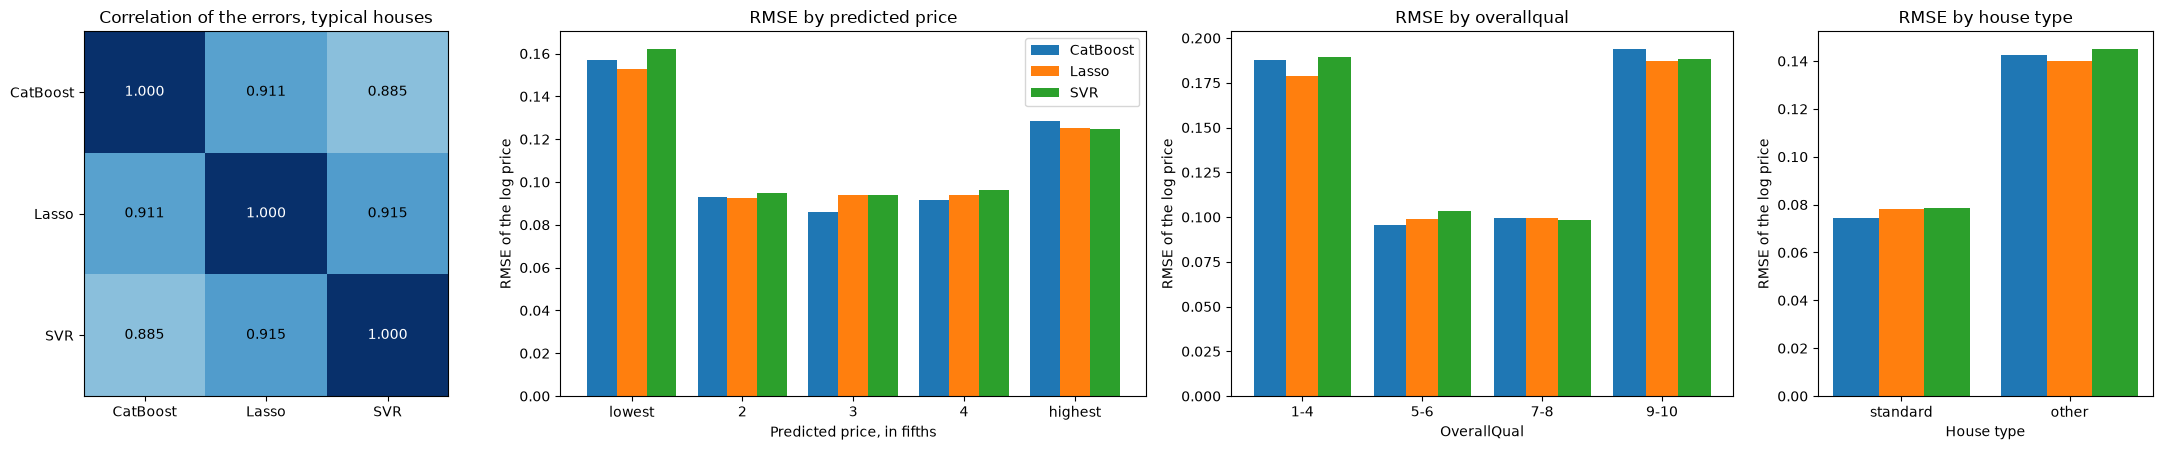

In [3]:
frame = oof[0]
e = pd.DataFrame({name: frame["Actual"] - frame[name] for name in MODELS})
raw = train.loc[e.index]
correlation = e[typical].corr()
print("Correlation of the errors on the typical houses:")
display(correlation.round(3))

t_statistic = lambda values: values.mean() / (values.std() / np.sqrt(len(values)))
# Standard houses: a normal sale, an OverallQual of 5 to 7, built in 1950 or later.
standard = (raw["SaleCondition"] == "Normal") & raw["OverallQual"].between(5, 7) & (raw["YearBuilt"] >= 1950)
groups = {
    "Predicted price": pd.qcut(frame["CatBoost"], 5, labels=["lowest", "2", "3", "4", "highest"]).astype(str),
    "OverallQual": pd.cut(raw["OverallQual"], [0, 4, 6, 8, 10], labels=["1-4", "5-6", "7-8", "9-10"]).astype(str),
    "Living area": pd.qcut(raw["GrLivArea"], 3, labels=["small", "middle", "large"]).astype(str),
    "House type": pd.Series(np.where(standard, "standard", "other"), index=raw.index),
}
order = {"Predicted price": ["lowest", "2", "3", "4", "highest"], "OverallQual": ["1-4", "5-6", "7-8", "9-10"], "Living area": ["small", "middle", "large"], "House type": ["standard", "other"]}
rows = []
for title, labels in groups.items():
    for level in order[title]:
        members = labels.index[labels == level]
        row = {"group": f"{title}: {level}", "houses": len(members)}
        row.update({name: rmse(e.loc[members, name]) for name in MODELS})
        # A negative t means the linear-family model is better than CatBoost.
        row.update({f"t, {name}": t_statistic(e.loc[members, name] ** 2 - e.loc[members, "CatBoost"] ** 2) for name in ["Lasso", "SVR"]})
        rows.append(row)
segments = pd.DataFrame(rows)
display(segments.round(3))

fig, axes = plt.subplots(1, 4, figsize=(22, 4.6), gridspec_kw={"width_ratios": [1, 1.4, 1.2, 0.8]})
image = axes[0].imshow(correlation, vmin=0.8, vmax=1, cmap="Blues")
axes[0].set_xticks(range(3), MODELS)
axes[0].set_yticks(range(3), MODELS)
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{correlation.iloc[i, j]:.3f}", ha="center", va="center", color="white" if correlation.iloc[i, j] > 0.95 else "black")
axes[0].set_title("Correlation of the errors, typical houses")
for ax, title in zip(axes[1:], ["Predicted price", "OverallQual", "House type"]):
    part = segments[segments["group"].str.startswith(title)]
    positions = np.arange(len(part))
    for offset, name in zip([-0.27, 0, 0.27], MODELS):
        ax.bar(positions + offset, part[name], 0.27, label=name)
    ax.set_xticks(positions, [label.split(": ")[1] for label in part["group"]])
    ax.set(xlabel=title + (", in fifths" if title == "Predicted price" else ""), ylabel="RMSE of the log price", title=f"RMSE by {title.lower()}")
axes[1].legend()
plt.tight_layout()
plt.show()

##### Findings:
- On the typical houses the errors of CatBoost and the lasso have a correlation of 0.911, CatBoost and the SVR 0.885, and the lasso and the SVR 0.915. So the SVR is the model least like CatBoost, and the lasso is about as like the SVR as it is like CatBoost.
- CatBoost is better in the middle. In the third fifth of the predicted prices its RMSE is 0.086, against 0.094 for both the lasso and the SVR (2.5 and 2.4 standard errors). For the middle-sized houses it is 0.107 against 0.114 and 0.116 (3.1 and 2.6), and for the standard houses 0.074 against 0.078 and 0.079 (2.5 and 2.0).
- The lasso and the SVR are better at the high end. In the highest fifth of the predicted prices both have an RMSE of 0.125, against 0.128 for CatBoost, and for an `OverallQual` of 9 to 10 0.187 and 0.189 against 0.194, all within 1.1 standard errors.
- At the low end only the lasso is better. In the lowest fifth of the predicted prices its RMSE is 0.153 against 0.157 for CatBoost and 0.162 for the SVR, for an `OverallQual` of 1 to 4 it is 0.179 against 0.188 and 0.190, and for the small houses 0.112 against 0.117 and 0.119, within 1.9 standard errors.

##### Decision:
Combine the models with one set of weights for all the houses. CatBoost is clearly better in the middle and the others only a little better at the ends, so weights that depend on the predicted price would rest on small differences.

## 4. The Weights
We compare three combinations: CatBoost with the lasso, CatBoost with the SVR, and CatBoost with both. For each we look at the error against the share of the other models, learn the weights on all the houses, and ask how well the data determines them: by a bootstrap, which draws the houses again with replacement, by learning them in each fold, and on the second split. We then test them fairly, by learning them on four folds and testing them on the fifth. We ask:
- Which combination has the lowest error, and is it better than CatBoost alone on both splits?
- What are the best weights, and how well does the data determine them?

CatBoost alone: {0: 0.1145, 1: 0.1161}


,Split,Combination,Weights,"Share, bootstrap 5% to 95%","Tested fairly, all houses",Without the two outliers,t against CatBoost
0,0,CatBoost and lasso,[0.51],0.39 to 0.64,0.1120,0.1081,-3.0673
1,0,CatBoost and SVR,[0.38],0.27 to 0.49,0.1126,0.1087,-2.7791
2,0,"CatBoost, lasso and SVR","[0.39, 0.19]",0.44 to 0.71,0.1117,0.1078,-3.1995
3,1,CatBoost and lasso,[0.6],0.47 to 0.74,0.1128,0.1072,-3.3222
4,1,CatBoost and SVR,[0.53],0.42 to 0.65,0.1127,0.1072,-3.4562
5,1,"CatBoost, lasso and SVR","[0.37, 0.34]",0.57 to 0.86,0.1119,0.1063,-3.7992


Weights of the lasso and the SVR learned in each fold, CatBoost, lasso and SVR:


,Split 0,Split 1
1,"[0.41, 0.16]","[0.35, 0.32]"
2,"[0.44, 0.18]","[0.41, 0.3]"
3,"[0.32, 0.24]","[0.36, 0.36]"
4,"[0.38, 0.17]","[0.36, 0.41]"
5,"[0.4, 0.18]","[0.34, 0.34]"


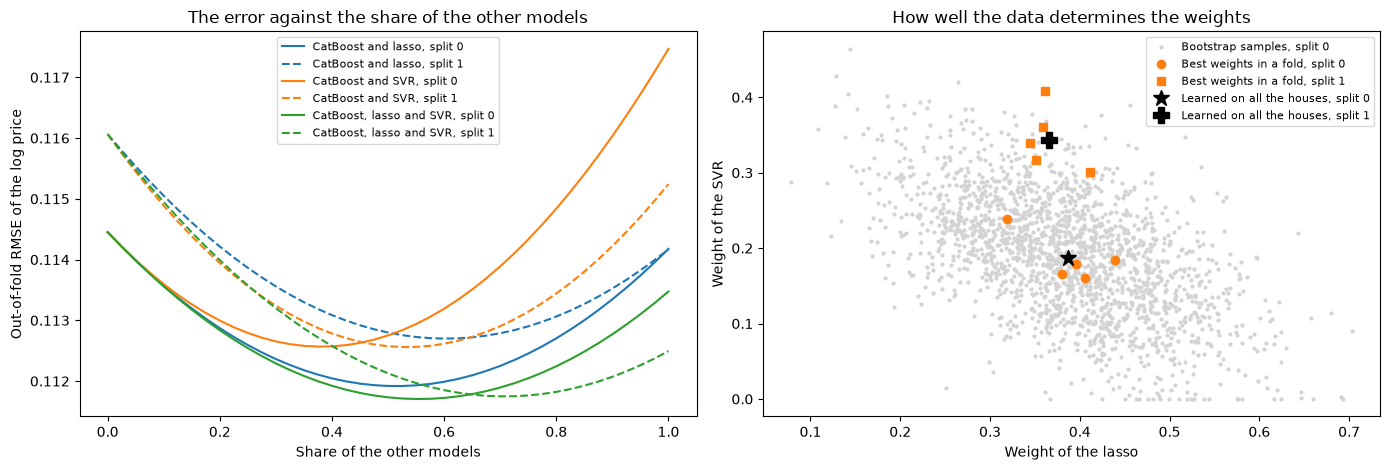

In [4]:
COMBINATIONS = {"CatBoost and lasso": ["Lasso"], "CatBoost and SVR": ["SVR"], "CatBoost, lasso and SVR": ["Lasso", "SVR"]}


def learn_weights(frame, index, members):
    # The weights of the members, from the differences to CatBoost. CatBoost gets one minus their sum.
    C = frame["CatBoost"].to_numpy()[index]
    differences = np.column_stack([frame[name].to_numpy()[index] - C for name in members])
    weights = nnls(differences, frame["Actual"].to_numpy()[index] - C)[0]
    return weights / max(1, weights.sum())


def combine(frame, members, weights):
    C = frame["CatBoost"].to_numpy()
    return C + sum(w * (frame[name].to_numpy() - C) for w, name in zip(weights, members))


rows, bootstrap_weights, fold_weights, learned = [], {}, {}, {}
for split, frame in oof.items():
    Y, fold_of, everyone = frame["Actual"].to_numpy(), frame["Fold"].to_numpy(), np.arange(len(frame))
    catboost_squared = (Y - frame["CatBoost"].to_numpy()) ** 2
    for title, members in COMBINATIONS.items():
        weights = learn_weights(frame, everyone, members)
        learned[(split, title)] = weights
        # Tested fairly: the weights are learned on four folds and tested on the fifth.
        nested = np.zeros(len(Y))
        for fold in range(1, 6):
            fold_weights[(split, title, fold)] = learn_weights(frame, np.where(fold_of != fold)[0], members)
            nested[fold_of == fold] = combine(frame, members, fold_weights[(split, title, fold)])[fold_of == fold]
        draws = np.random.default_rng(0)
        bootstrap_weights[(split, title)] = np.array([learn_weights(frame, draws.integers(0, len(Y), len(Y)), members) for _ in range(2000)])
        low, high = np.percentile(bootstrap_weights[(split, title)].sum(axis=1), [5, 95])
        difference = (Y - nested) ** 2 - catboost_squared
        rows.append({"Split": split, "Combination": title, "Weights": np.round(weights, 2).tolist(), "Share, bootstrap 5% to 95%": f"{low:.2f} to {high:.2f}",
                     "Tested fairly, all houses": rmse(Y - nested), "Without the two outliers": rmse((Y - nested)[typical]), "t against CatBoost": t_statistic(difference)})
results = pd.DataFrame(rows)
print("CatBoost alone:", {split: round(rmse(frame["Actual"] - frame["CatBoost"]), 4) for split, frame in oof.items()})
display(results.round(4))
print("Weights of the lasso and the SVR learned in each fold, CatBoost, lasso and SVR:")
display(pd.DataFrame({f"Split {split}": {fold: np.round(fold_weights[(split, "CatBoost, lasso and SVR", fold)], 2).tolist() for fold in range(1, 6)} for split in oof}))

# The error against the share of the other models, which are averaged when there are two.
shares = np.linspace(0, 1, 41)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for (title, members), colour in zip(COMBINATIONS.items(), ["tab:blue", "tab:orange", "tab:green"]):
    for split, style in [(0, "-"), (1, "--")]:
        frame = oof[split]
        curve = [rmse(frame["Actual"] - combine(frame, members, [share / len(members)] * len(members))) for share in shares]
        axes[0].plot(shares, curve, style, color=colour, label=f"{title}, split {split}")
axes[0].set(xlabel="Share of the other models", ylabel="Out-of-fold RMSE of the log price", title="The error against the share of the other models")
axes[0].legend(fontsize=8)
cloud = bootstrap_weights[(0, "CatBoost, lasso and SVR")]
axes[1].scatter(cloud[:, 0], cloud[:, 1], s=4, color="lightgrey", label="Bootstrap samples, split 0")
for fold in range(1, 6):
    for split, marker in [(0, "o"), (1, "s")]:
        w = fold_weights[(split, "CatBoost, lasso and SVR", fold)]
        axes[1].plot(w[0], w[1], marker, color="tab:orange", label=f"Best weights in a fold, split {split}" if fold == 1 else None)
for split, marker in [(0, "*"), (1, "P")]:
    w = learned[(split, "CatBoost, lasso and SVR")]
    axes[1].plot(w[0], w[1], marker, color="black", markersize=12, label=f"Learned on all the houses, split {split}")
axes[1].set(xlabel="Weight of the lasso", ylabel="Weight of the SVR", title="How well the data determines the weights")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

##### Findings:
- Tested fairly, all three combinations are better than CatBoost alone on both splits, by 2.8 to 3.8 standard errors. CatBoost alone has an RMSE of 0.1145 and 0.1161 on all the houses. With the lasso it is 0.1120 and 0.1128, with the SVR 0.1126 and 0.1127, and with both 0.1117 and 0.1119.
- So CatBoost with the SVR is not better than with the lasso. It is the same on split 1 and worse on split 0. With both models it is best on both splits, and without the two outliers too (0.1078 and 0.1063).
- The learned weights of the lasso and the SVR are 0.39 and 0.19 on split 0 and 0.37 and 0.34 on split 1, so together they get 0.58 and 0.71 of the combination. The bootstrap gives 0.44 to 0.71 and 0.57 to 0.86 for their share, so the data determines it only to within about 0.3.
- The weight of the lasso is stable, at 0.32 to 0.44 in every fold of both splits. The weight of the SVR is not: 0.16 to 0.24 in the folds of split 0 and 0.30 to 0.41 in the folds of split 1.

##### Decision:
Combine CatBoost, the lasso and the SVR.

The learned weights give the lasso and the SVR more than half of the combination. One reason could be that each model in the cross-validation sees only four fifths of the houses, while the final models see all of them, and CatBoost may gain more from the extra houses than the linear models. If so, the best weights would fall as the models see more houses. We also ask how much of the gain is kept if the learned weights are taken halfway towards CatBoost alone, as a hedge against weights that the data determines only roughly. We ask:
- Do the best weights change when the models are fitted on two thirds, four fifths or nine tenths of the houses?
- How much of the gain over CatBoost do the weights keep when they are taken halfway towards CatBoost alone?

In [5]:
# The same models with 3 and 10 folds on split 0. The 5 folds are those above.
by_size = {5: oof[0]}
for n_folds in (3, 10):
    by_size[n_folds] = predictions(linear_folds(n_folds, 0))
rows = []
for n_folds, frame in by_size.items():
    row = {"Folds": n_folds, "Share of the houses fitted": 1 - 1 / n_folds}
    row.update({f"RMSE, {name}": rmse(frame["Actual"] - frame[name]) for name in MODELS})
    row["Weights of the lasso and the SVR"] = np.round(learn_weights(frame, np.arange(len(frame)), ["Lasso", "SVR"]), 2).tolist()
    rows.append(row)
display(pd.DataFrame(rows).round(4))

# The weights learned on both splits together, and taken halfway towards CatBoost alone.
both = pd.concat([oof[0], oof[1]])
full = learn_weights(both, np.arange(len(both)), ["Lasso", "SVR"])
WEIGHTS = full / 2
print(f"Learned on both splits: CatBoost {1 - full.sum():.2f}, lasso {full[0]:.2f}, SVR {full[1]:.2f}. Halfway towards CatBoost: CatBoost {1 - WEIGHTS.sum():.2f}, lasso {WEIGHTS[0]:.2f}, SVR {WEIGHTS[1]:.2f}")
rows = {}
for split, frame in oof.items():
    Y, fold_of = frame["Actual"].to_numpy(), frame["Fold"].to_numpy()
    nested_full, nested_half = np.zeros(len(Y)), np.zeros(len(Y))
    for fold in range(1, 6):
        w = fold_weights[(split, "CatBoost, lasso and SVR", fold)]
        nested_full[fold_of == fold] = combine(frame, ["Lasso", "SVR"], w)[fold_of == fold]
        nested_half[fold_of == fold] = combine(frame, ["Lasso", "SVR"], w / 2)[fold_of == fold]
    base = rmse(Y - frame["CatBoost"])
    rows[f"Split {split}"] = {"CatBoost alone": base, "Learned weights, tested fairly": rmse(Y - nested_full), "Halfway towards CatBoost, tested fairly": rmse(Y - nested_half),
                              "Share of the gain kept": (base - rmse(Y - nested_half)) / (base - rmse(Y - nested_full))}
display(pd.DataFrame(rows).round(4))

,Folds,Share of the houses fitted,"RMSE, CatBoost","RMSE, Lasso","RMSE, SVR",Weights of the lasso and the SVR
0,5,0.8000,0.1145,0.1142,0.1175,"[0.39, 0.19]"
1,3,0.6667,0.1159,0.1131,0.1138,"[0.37, 0.36]"
2,10,0.9000,0.1139,0.1132,0.1135,"[0.32, 0.36]"


Learned on both splits: CatBoost 0.36, lasso 0.38, SVR 0.26. Halfway towards CatBoost: CatBoost 0.68, lasso 0.19, SVR 0.13


,Split 0,Split 1
CatBoost alone,0.1145,0.1161
"Learned weights, tested fairly",0.1117,0.1119
"Halfway towards CatBoost, tested fairly",0.1124,0.1129
Share of the gain kept,0.7576,0.7599


##### Findings:
- The weights do not fall as the models see more houses. The lasso and the SVR get 0.37 and 0.36 with two thirds of the houses, 0.39 and 0.19 with four fifths and 0.32 and 0.36 with nine tenths. CatBoost does gain from more houses, with an RMSE of 0.1159, 0.1145 and 0.1139, but so do the others, and the weights change with the split more than with the number of houses. So the size of the fitting houses does not explain the large weights.
- Learned on the out-of-fold predictions of both splits together, the weights are 0.36 for CatBoost, 0.38 for the lasso and 0.26 for the SVR. Halfway towards CatBoost alone they are 0.68, 0.19 and 0.13.
- Tested fairly, the weights taken halfway have an RMSE of 0.1124 and 0.1129, against 0.1117 and 0.1119 for the learned weights and 0.1145 and 0.1161 for CatBoost alone. They keep 76% of the gain over CatBoost on both splits.

##### Decision:
Use the weights taken halfway towards CatBoost: 0.68 for CatBoost, 0.19 for the lasso and 0.13 for the SVR. The data determines the share of the lasso and the SVR only to within about 0.3, and the weight of the SVR changes with the split. Taken halfway, the weights keep three quarters of the gain, and they move the predictions only half as far from CatBoost if the learned weights are too large for the test houses.

## 5. Submission
We fit CatBoost, as the average of three seeds, on all the train houses with the two outliers, and the lasso and the SVR on all the train houses without them, and predict the test houses. The predictions are combined with the weights of section 4, with CatBoost alone for the test houses outside the range of the lasso and the SVR, and the file is saved as `stack_v05.csv` by `save_submission`. We ask:
- Which test houses are outside the range, and where does the combination differ most from CatBoost?

In [6]:
catboost_test = catboost_predict(train, test)
fit_clean, test_clean, fit_features, test_features = linear_data(train, test)
mean, std = fit_standardiser(fit_features)
Z_fit, Z_test = standardise(fit_features, mean, std), standardise(test_features, mean, std)
y = np.log(fit_clean["SalePrice"]).to_numpy()
G, c = gram(Z_fit, y - y.mean())
outside = outside_range(fit_clean, test_clean)
test_predictions = pd.DataFrame({
    "CatBoost": catboost_test,
    "Lasso": np.where(outside, catboost_test, y.mean() + Z_test @ elastic_net(G, c, ALPHA, 1.0)),
    "SVR": np.where(outside, catboost_test, y.mean() + SVR(kernel="rbf", **SVR_SETTINGS).fit(Z_fit, y - y.mean()).predict(Z_test)),
}, index=test_features.index)

stack = combine(test_predictions, ["Lasso", "SVR"], WEIGHTS)
prices = pd.Series(np.exp(stack), index=test_features.index)
gap = pd.Series(stack - catboost_test, index=test_features.index)
moved = gap.abs().sort_values(ascending=False).head(5).index
display(pd.concat([np.exp(test_predictions.loc[moved]), prices[moved].rename("Combination")], axis=1).round(0))
print("Test houses outside the range, predicted by CatBoost alone:", list(test_features.index[outside]), "at", f"{prices[test_features.index[outside]].round(0).tolist()}")
print(f"Weights: CatBoost {1 - WEIGHTS.sum():.2f}, lasso {WEIGHTS[0]:.2f}, SVR {WEIGHTS[1]:.2f}. Mean absolute difference from CatBoost: {gap.abs().mean():.4f} in the log price")
print(f"Predicted price: lowest {prices.min():,.0f}, median {prices.median():,.0f}, highest {prices.max():,.0f}")
print("Saved:", save_submission(test_features.index, prices.to_numpy(), "stack", 5))

,CatBoost,Lasso,SVR,Combination
Id,,,,
2399,58871.0,74714.0,74953.0,63573.0
2469,72360.0,89222.0,92266.0,77730.0
2580,98601.0,79942.0,79101.0,92059.0
2040,250180.0,296025.0,309979.0,265654.0
1790,69073.0,80871.0,84807.0,73111.0


Test houses outside the range, predicted by CatBoost alone: [2550] at [231474.0]
Weights: CatBoost 0.68, lasso 0.19, SVR 0.13. Mean absolute difference from CatBoost: 0.0107 in the log price
Predicted price: lowest 38,819, median 157,501, highest 527,948
Saved: ../submissions/stack_v05.csv


##### Findings:
- `Id` 2550 is the only test house outside the range of the lasso and the SVR, so it is predicted by CatBoost alone, at 231,474.
- The combination differs from CatBoost by 0.0107 in the log price on average. It differs most for `Id` 2399, where CatBoost predicts 58,871, the lasso 74,714, the SVR 74,953 and the combination 63,573, and for `Id` 2469 (72,360 to 77,730), `Id` 2580 (98,601 to 92,059), `Id` 2040 (250,180 to 265,654) and `Id` 1790. For all five the lasso and the SVR agree with each other and differ from CatBoost in the same direction.
- The predicted prices go from 38,819 to 527,948, with a median of 157,501.